# 2. The four routes and their files

A **route** is one complete recipe: compress the model, then fine-tune it. All four routes were adjusted until
their real files are approximately the same size (about 9.8 MB).

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # run from the repository root
sys.path.insert(0, "src")
import numpy as np
from IPython.display import Image, display

import ast
def show(path, *names):
    """Print the real source of functions/classes from a file in src/ (read directly, never copied)."""
    src = open(path).read(); lines = src.splitlines(); tree = ast.parse(src)
    nodes = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
    for name in names:
        n = nodes[name]; start = n.decorator_list[0].lineno if n.decorator_list else n.lineno
        print(f"# ---- {path}, lines {start}-{n.end_lineno}")
        print("\n".join(lines[start - 1:n.end_lineno])); print()

def show_lines(path, start_text, end_text):
    """Print a block of a script, from the line containing start_text to the line containing end_text."""
    lines = open(path).read().splitlines()
    i = next(k for k, l in enumerate(lines) if start_text in l)
    j = next(k for k, l in enumerate(lines[i + 1:], i + 1) if end_text in l)
    print(f"# ---- {path}, lines {i + 1}-{j + 1}"); print("\n".join(lines[i:j + 1]))

## 2.1 Quantisation on three real numbers

Three weights are rounded to 3 bits (8 allowed values). The file stores the small whole numbers (codes) and
one scale. Multiplying them back gives the weights the model actually uses.

In [2]:
import torch
from phase1_audit import quantize_groupwise
w = torch.tensor([[0.12, -0.40, 0.05]])
codes, scale, err = quantize_groupwise(w, bits=3, group_size=3)
signed = codes.astype(int) - 4                     # codes are stored with an offset of 4
print("weights :", [round(x, 2) for x in w.tolist()[0]])
print("codes   :", signed.tolist(), " scale:", round(float(scale[0]), 4))
print("restored:", [round(float(c) * float(scale[0]), 3) for c in signed])

weights : [0.12, -0.4, 0.05]
codes   : [1, -3, 0]  scale: 0.1333
restored: [0.133, -0.4, 0.0]


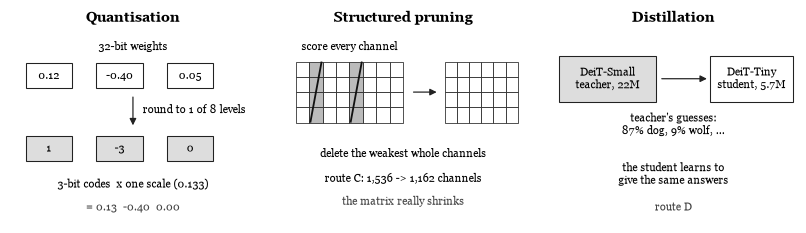

In [3]:
display(Image("proposal/figs/png/fig_techniques.png", width=760))

### The code for each compression method

- `quantize_ternary`: every weight becomes −1, 0 or +1 with one scale per row (Ternary Weight Networks rule).
- `pack_base3`: five ternary values fit in one byte, because 3⁵ = 243 ≤ 256.
- `prune_mlp_channels`: removes the weakest whole channels from each MLP layer (structured pruning).

In [4]:
show("src/build_routes.py", "quantize_ternary", "pack_base3", "prune_mlp_channels")

# ---- src/build_routes.py, lines 38-54
def quantize_ternary(w: torch.Tensor):
    """
    Weights -> {-1, 0, +1} with one FP16 scale per output channel.

    Threshold delta = 0.7 * mean(|w|) is the Ternary Weight Networks rule.
    Returns (codes in {0,1,2}, per-row scales, max_abs_err, zero_fraction).
    """
    x = w.detach().float().reshape(w.shape[0], -1)
    delta = 0.7 * x.abs().mean(dim=1, keepdim=True)
    tern = torch.zeros_like(x)
    tern[x > delta] = 1.0
    tern[x < -delta] = -1.0
    nz = tern.abs().sum(dim=1, keepdim=True).clamp(min=1)
    alpha = ((x.abs() * tern.abs()).sum(dim=1, keepdim=True) / nz).half().float()
    err = (tern * alpha - x).abs().max().item()
    zero_frac = (tern == 0).float().mean().item()
    return (tern + 1).to(torch.uint8).reshape(-1).numpy(), alpha.reshape(-1), err, zero_frac

# ---- src/build_routes.py, lines 57-65
def pack_base3(codes: np.ndarray) -> bytes:
    """5 ternary codes per byte: 3**5 = 243 <= 255.  Exactly 1.600 bits/weight."""

## 2.2 The four route files

Each route has one setting that was searched until its file was just under the target. All three seeds of a
route have byte-identical sizes.

In [5]:
import os, glob
setting = {"A": "36 weights per scale", "B": "15 sensitive layers at 8 bits",
           "C": "MLP channels pruned (knob 0.24375)", "D": "38 layers kept at 16 bits"}
what = {"A": "3-bit", "B": "ternary (-1, 0, +1)", "C": "4-bit + pruning", "D": "DeiT-Tiny, distilled, 8-bit"}
sizes = {}
for r in "ABCD":
    s = {os.path.getsize(f"evidence/models/ChotaDeiT-{r}-s{k}.bin") for k in (0, 1, 2)}
    assert len(s) == 1
    sizes[r] = s.pop() / 1e6
    print(f"route {r}  {what[r]:<28}{sizes[r]:.3f} MB   setting: {setting[r]}")
print(f"\nspread between largest and smallest: {100*(max(sizes.values())/min(sizes.values())-1):.2f}%")

route A  3-bit                       9.718 MB   setting: 36 weights per scale
route B  ternary (-1, 0, +1)         9.785 MB   setting: 15 sensitive layers at 8 bits
route C  4-bit + pruning             9.796 MB   setting: MLP channels pruned (knob 0.24375)
route D  DeiT-Tiny, distilled, 8-bit 9.765 MB   setting: 38 layers kept at 16 bits

spread between largest and smallest: 0.80%


### The code that hits the same size

`make_policy` turns a route and its one setting into a plan for every layer. `build_route` searches that setting
(binary search) by writing the real file with `write_model` and measuring it, until the file lands just under
the target. Accuracy is never used.

In [6]:
show("src/build_routes.py", "make_policy", "build_route", "write_model")

# ---- src/build_routes.py, lines 152-169
def make_policy(route, state, knob, order):
    """knob meaning: A=group size, B/D=#layers promoted to higher precision, C unused."""
    protect = set(order[:int(knob)]) if route in ("B", "D") else set()

    def policy(name, w):
        comp = component_of(name)
        if not is_quantizable(name, w):
            return ("fp16", None, None)
        if route == "A":
            return ("int", 3, int(knob))
        if route == "B":
            return ("int", 8, 128) if name in protect else ("ternary", None, None)
        if route == "C":
            return ("int", 4, 128)                      # everything, incl. patch_embed + head
        if route == "D":
            return ("fp16", None, None) if name in protect else ("int", 8, 128)
        raise ValueError(route)
    return policy

# ---- src/build_routes.py, lines 172-216
def build_route(route, base_state, target_bytes, tol, outdir):
    """Binary-search the knob until measured size is withi

## 2.3 The files really are the models

`src/decode_bin.py` reads a file back into a working PyTorch model. Below: route C really has 1,162 channels in
each MLP layer (374 of 1,536 pruned), and route D really is the smaller DeiT-Tiny (width 192).

In [7]:
from decode_bin import build_model
c = build_model("evidence/models/ChotaDeiT-C-s0.bin", device="cpu")
d = build_model("evidence/models/ChotaDeiT-D-s0.bin", device="cpu")
print("route C, MLP channels per block:", sorted({b.mlp.fc1.out_features for b in c.blocks}), "of 1536")
print("route D, token width:", d.embed_dim, "(DeiT-Small is 384)")

route C, MLP channels per block: [1162] of 1536
route D, token width: 192 (DeiT-Small is 384)


In [8]:
show("src/decode_bin.py", "decode", "build_model")

# ---- src/decode_bin.py, lines 57-84
def decode(path, group=None):
    """Return (state_dict of float32 tensors, header)."""
    group = group or group_for(path)
    header, payload = read_bin(path)
    state, off = OrderedDict(), 0
    for name, kind, shape, cb, sb in header:
        n = int(np.prod(shape)) if shape else 1
        code_buf = payload[off:off + cb]; off += cb
        scale_buf = payload[off:off + sb]; off += sb
        if kind == "f16":
            t = torch.from_numpy(np.frombuffer(code_buf, dtype=np.float16).astype(np.float32).copy())
        elif kind == "t3":
            codes = _unpack_base3(code_buf, n) - 1                       # {-1, 0, +1}
            alpha = np.frombuffer(scale_buf, dtype=np.float16).astype(np.float32)
            t = torch.from_numpy((codes.reshape(shape[0], -1) * alpha[:, None]).astype(np.float32))
        elif kind.startswith("i"):
            bits = int(kind[1:]); qmax = 2 ** (bits - 1) - 1
            g = min(group, n)
            q = _u

## 2.4 Round trip: decode, re-encode, compare bytes

Each file is decoded into a model and written again. The new file must be byte-for-byte identical.
This runs on the four seed-0 route files; `python src/decode_bin.py --roundtrip evidence/models/*.bin` checks all 21.

In [9]:
import subprocess
r = subprocess.run([sys.executable, "src/decode_bin.py", "--roundtrip",
                    *[f"evidence/models/ChotaDeiT-{x}-s0.bin" for x in "ABCD"]],
                   capture_output=True, text=True, check=True)
print(r.stdout)

  ChotaDeiT-A-s0.bin           group 36    152 tensors   9,718,109 B  round-trip BYTE-IDENTICAL
  ChotaDeiT-B-s0.bin           group 128   152 tensors   9,784,567 B  round-trip BYTE-IDENTICAL
  ChotaDeiT-C-s0.bin           group 128   152 tensors   9,795,937 B  round-trip BYTE-IDENTICAL
  ChotaDeiT-D-s0.bin           group 128   152 tensors   9,765,199 B  round-trip BYTE-IDENTICAL

4/4 files decode and re-encode byte-identically



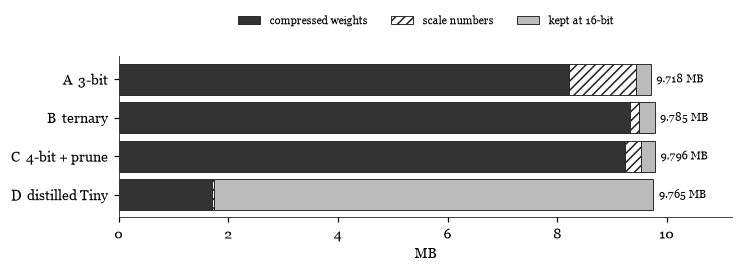

In [10]:
display(Image("proposal/figs/png/fig2_inside_files.png", width=700))